# Chapter 03 — Stats Review: The Most Dangerous Equation & Regression
Rewritten using the `probability` library (based on Matheus Facure's *Causal Inference in Python*).

In [1]:
import set_paths
import numpy as np
import pandas as pd
from pandas import DataFrame
import matplotlib.pyplot as plt
from make_data import load_wage, load_enem_scores
from probability.distributions import Ratio, Boolean, Nominal, Normal, StudentsT
from probability.models import BayesianLinearRegression

## 3.1 The Most Dangerous Equation: Sample Size and Variance
Howard Wainer famously observed that both the highest-performing and lowest-performing schools tend to be small. The reason is the sampling standard error of the mean:
$$SE = \frac{\sigma}{\sqrt{n}}$$
We wrap school test scores in empirical `Ratio` distributions to inspect the sampling distribution of the mean across school sizes.

In [2]:
enem = load_enem_scores()
small_scores = Ratio(enem[enem['number_of_students'] < 50]['avg_score'].rename('Small Schools'))
large_scores = Ratio(enem[enem['number_of_students'] > 300]['avg_score'].rename('Large Schools'))

print(f"Small schools (n={len(small_scores)}): mean={small_scores.mean():.2f}, SE={small_scores.se():.3f}, 95% CI={small_scores.ci(0.95)}")
print(f"Large schools (n={len(large_scores)}): mean={large_scores.mean():.2f}, SE={large_scores.se():.3f}, 95% CI={large_scores.ci(0.95)}")

Small schools (n=7441): mean=51.59, SE=0.109, 95% CI=(np.float64(51.372603437590264), np.float64(51.801722593857114))
Large schools (n=3303): mean=45.25, SE=0.122, 95% CI=(np.float64(45.01007240020171), np.float64(45.48665178992847))


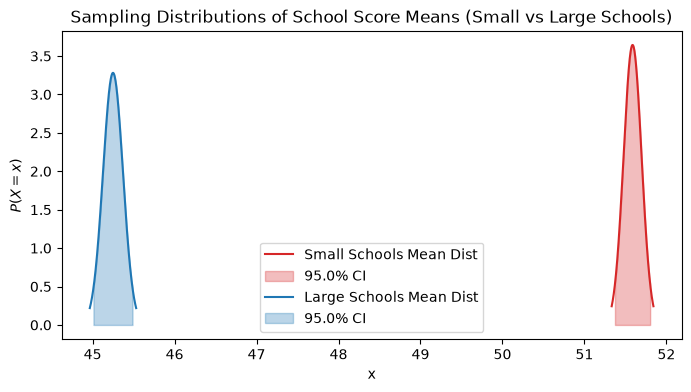

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
small_scores.mean_dist().plot(ci=0.95, ax=ax, color='tab:red', label='Small Schools Mean Dist')
large_scores.mean_dist().plot(ci=0.95, ax=ax, color='tab:blue', label='Large Schools Mean Dist')
ax.set_title("Sampling Distributions of School Score Means (Small vs Large Schools)")
ax.legend();

## 3.2 Confounding and Regression (`wage.csv`)
In observational studies, naive comparisons between treatment and outcome are confounded by common causes. Here we study the return to education (`educ`) on `wage` while controlling for covariates: `exper` (experience), `tenure`, and `IQ`.

In [4]:
wage_df = load_wage().dropna()
wage_df[['wage', 'educ', 'exper', 'tenure', 'IQ']].head()

,wage,educ,exper,tenure,IQ
0,769,12,11,2,93
2,825,14,11,9,108
3,650,12,13,7,96
4,562,11,14,5,74
6,600,10,13,0,91


## 3.3 Closed-Form Bayesian Linear Regression (`BayesianLinearRegression`)
We fit an exact conjugate Normal-Inverse-Gamma linear model. In `probability`, regression coefficients are returned as first-class `StudentsT` distribution objects, and the residual variance is returned as an `InverseGamma` distribution object!

In [5]:
features = ['educ', 'exper', 'tenure', 'IQ']
model = BayesianLinearRegression.fit(
    X=wage_df[features],
    y=wage_df['wage'],
    fit_intercept=True
)
model.summary()

,mean,std,hdi_95_lower,hdi_95_upper,P(>0),P(<0)
parameter,,,,,,
beta[intercept],-510.784198,139.885083,-785.455341,-236.113054,0.000141,9.998593e-01
beta[educ],56.215320,8.431223,39.660205,72.770435,1.000000,2.741851e-11
beta[exper],16.474763,3.995196,8.630001,24.319525,0.999979,2.101549e-05
beta[tenure],4.762853,3.007333,-1.142191,10.667898,0.943136,5.686414e-02
beta[IQ],4.957877,1.172235,2.656137,7.259616,0.999987,1.336200e-05
sigma_sq,138430.913489,NaN,123767.598138,153568.692864,1.000000,0.000000e+00


## 3.4 Marginal Posteriors and Forest Plot
Each coefficient posterior is an exact marginal `StudentsT` distribution with analytical mean, HDI, and directional probabilities.

In [6]:
beta_educ = model.coef('educ')
print("educ coefficient marginal posterior:", beta_educ)
print(f"Mean: {beta_educ.mu:.3f}, Std: {beta_educ.sigma:.3f}")
print(f"95% HDI: {beta_educ.hdi(0.95)}")
print(f"P(beta[educ] > 0): {model.prob_positive('educ'):.6f}")
print(f"P(beta[educ] > 40): {float(1.0 - beta_educ.cdf().at(40.0)):.4f}")

educ coefficient marginal posterior: StudentsT($\nu$=663.002, μ=56.215, σ=8.431)
Mean: 56.215, Std: 8.431
95% HDI: (np.float64(39.66020473467506), np.float64(72.77043500303253))
P(beta[educ] > 0): 1.000000
P(beta[educ] > 40): 0.9726


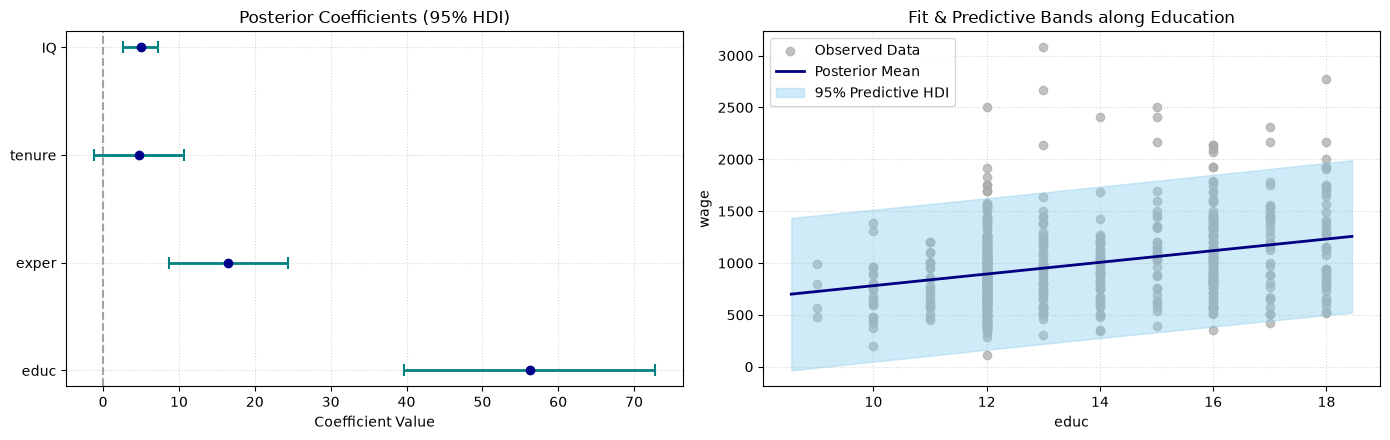

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
model.plot_coefficients(ax=axes[0], exclude_intercept=True)
axes[0].set_title("Posterior Coefficients (95% HDI)")
model.plot_fit(x_var='educ', ax=axes[1])
axes[1].set_title("Fit & Predictive Bands along Education")
plt.tight_layout();

## 3.5 Posterior Predictive Inference for New Observations
We can obtain individual predictive `StudentsT` distributions for new candidate profiles, incorporating both coefficient uncertainty and residual variance $\sigma^2$.

Predictive distribution for new candidate: StudentsT($\nu$=663.002, μ=1147.379, σ=372.192)
Point prediction: $1147.38
95% Predictive Interval: [$416.56, $1878.20]


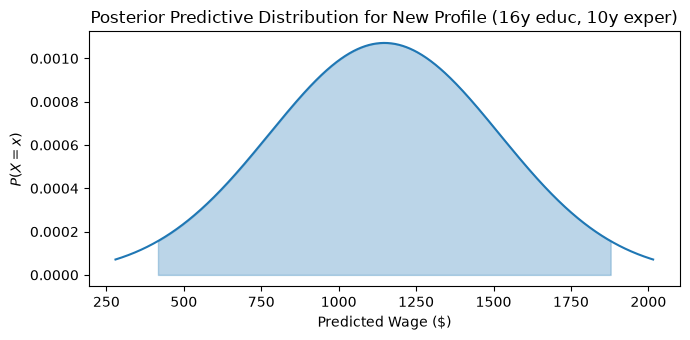

In [8]:
new_profile = pd.DataFrame({
    'educ': [16],
    'exper': [10],
    'tenure': [5],
    'IQ': [115]
})
pred_dist = model.predict_dist(new_profile).iloc[0]
pred_interval = model.predict_interval(new_profile, hdi=0.95).iloc[0]

print("Predictive distribution for new candidate:", pred_dist)
print(f"Point prediction: ${model.predict(new_profile).iloc[0]:.2f}")
print(f"95% Predictive Interval: [${pred_interval['hdi_95_lower']:.2f}, ${pred_interval['hdi_95_upper']:.2f}]")

fig, ax = plt.subplots(figsize=(7, 3.5))
pred_dist.plot(ci=0.95, ax=ax, color='tab:blue')
ax.set_title("Posterior Predictive Distribution for New Profile (16y educ, 10y exper)")
ax.set_xlabel("Predicted Wage ($)")
plt.tight_layout();